In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import networkx as nx
import random
from ipywidgets import interact

print("You have imported all the libraries.")

You have imported all the libraries.


In [ ]:
class Maze:
    def __init__(self, maze, start_position, goal_position):
        self.maze = maze
        self.maze_height = maze_layout.shape[0]
        self.maze_width = maze_layout.shape[1]
        self.start_position = start_position
        self.goal_position = goal_position

    def show_maze(self):
        plt.figure(figsize=(5,5))

        plt.imshow(self.maze, cmap='gray')
        plt.text(self.start_position[0], self.start_position[1], 'S', ha='center', va='center', color='red', fontsize=20)
        plt.text(self.goal_position[0], self.goal_position[1], 'G', ha='center', va='center', color='green', fontsize=20)
        plt.xticks([]), plt.yticks([])
        plt.show()

print("This code block has been run and the Maze class is now available for use.")

This code block has been run and the Maze class is now available for use.


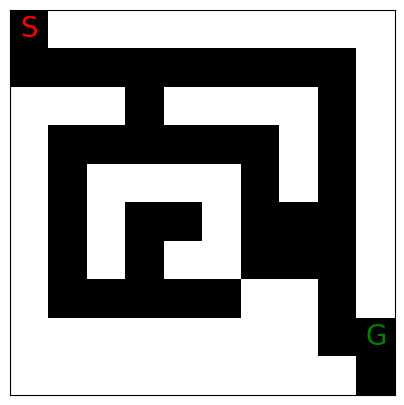

In [ ]:
maze_layout = np.array([
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 1, 1, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 0, 1, 0, 1],
    [1, 0, 1, 1, 1, 1, 0, 1, 0, 1],
    [1, 0, 1, 0, 0, 1, 0, 0, 0, 1],
    [1, 0, 1, 0, 1, 1, 0, 0, 0, 1],
    [1, 0, 0, 0, 0, 0, 1, 1, 0, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 0, 0],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 0]
])
maze = Maze(maze_layout, (0, 0), (9, 8))
maze.show_maze()

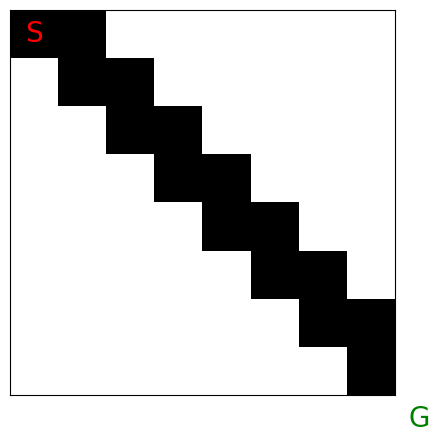

In [ ]:
m = 8
n = 8
maze_layout = (1- np.eye(m)) + (1-np.eye(m,k=1))

start_x = 0
start_y = 0
goal_x = n
goal_y = n
maze = Maze(maze_layout, (start_x, start_y), (goal_x, goal_y))
maze.show_maze()

Number of steps: 58
Total reward: 58


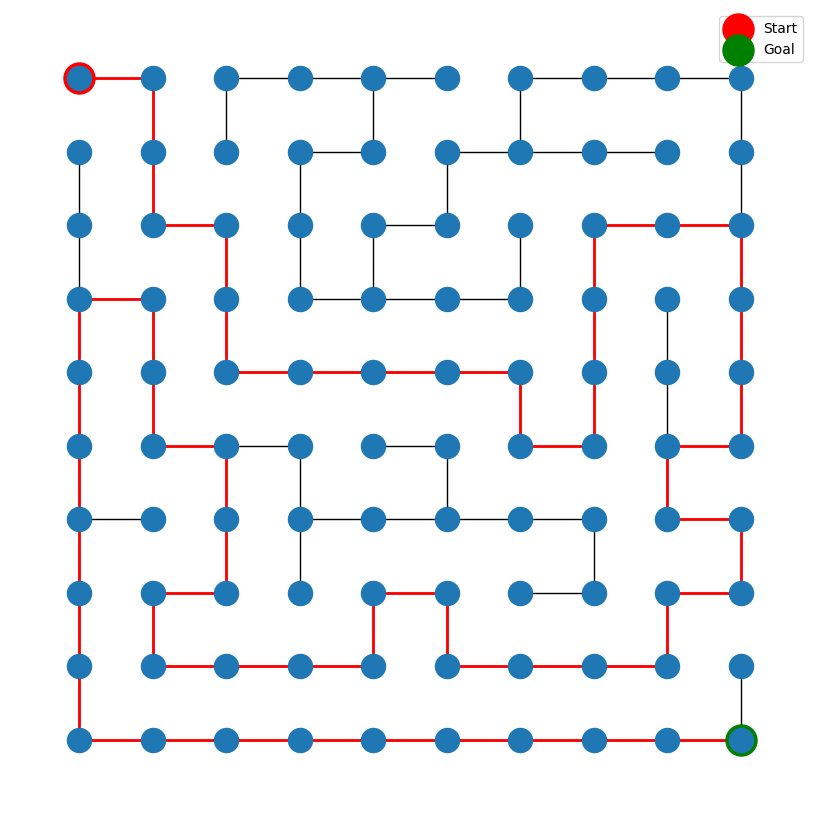

In [ ]:
size = 10

def generate_maze(size):
    maze = np.ones((size, size))
    stack = [(0, 0)]
    visited = set()
    edges = []

    while stack:
        x, y = stack[-1]
        visited.add((x, y))
        maze[x, y] = 0
        neighbors = [(x + dx, y + dy) for dx, dy in [(0,1), (1,0), (0,-1), (-1,0)]]
        neighbors = [(nx, ny) for nx, ny in neighbors if 0 <= nx < size and 0 <= ny < size and (nx, ny) not in visited]

        if neighbors:
            next_x, next_y = random.choice(neighbors)
            stack.append((next_x, next_y))
            edges.append(((x, y), (next_x, next_y)))
        else:
            stack.pop()

    return maze, edges

def create_graph(edges):
    G = nx.Graph()
    for edge in edges:
        G.add_edge(*edge)
    return G

def plot_maze(G, size, path=None):
    plt.figure(figsize=(8, 8))
    pos = { (x, y): (y, -x) for x in range(size) for y in range(size) }
    nx.draw(G, pos, node_size=300, with_labels=False, edge_color="black")
    if path:
        nx.draw_networkx_edges(G, pos, edgelist=list(zip(path, path[1:])), edge_color='red', width=2)
    plt.scatter([0], [0], color='red', s=500, label='Start')
    plt.scatter([size - 1], [-(size - 1)], color='green', s=500, label='Goal')
    plt.legend()
    plt.show()

maze, edges = generate_maze(size)
G = create_graph(edges)

path = nx.shortest_path(G, source=(0, 0), target=(size - 1, size - 1))

num_steps = len(path) - 1

reward_per_step = 1
total_reward = num_steps * reward_per_step

print(f"Number of steps: {num_steps}")
print(f"Total reward: {total_reward}")

plot_maze(G, size, path)

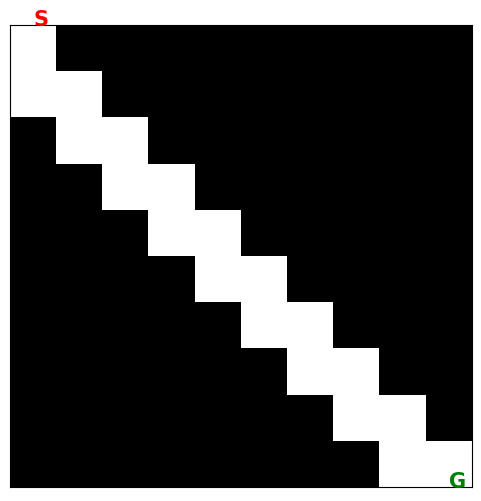

In [ ]:
def create_step_maze(size):
    maze = np.ones((size, size))
    for i in range(size - 1):
        maze[i, i] = 0
        if i + 1 < size:
            maze[i + 1, i] = 0
    maze[size - 1, size - 1] = 0
    return maze

def plot_maze(maze):
    size = maze.shape[0]
    plt.figure(figsize=(6, 6))
    plt.imshow(maze, cmap='binary')
    plt.xticks([])
    plt.yticks([])

    plt.text(0, -0.5, 'S', color='red', fontsize=15, fontweight='bold')
    plt.text(size - 1, size - 0.5, 'G', color='green', fontsize=15, fontweight='bold')

    plt.show()

size = 10
maze = create_step_maze(size)
plot_maze(maze)


In [ ]:
import numpy as np

maze = np.array([
    [0, 1, 0, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 0, 1, 0],
    [1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
])

player_pos = [0, 0]
goal_pos = [4, 4]

def print_maze():
    for i in range(5):
        row = ""
        for j in range(5):
            if [i, j] == player_pos:
                row += " P "
            elif [i, j] == goal_pos:
                row += " G "
            elif maze[i, j] == 1:
                row += " █ "
            else:
                row += " . "
        print(row)
    print("\n")

print("🚀 Maze O‘yini 🚀")
print("Harakat qilish: W (↑), S (↓), A (←), D (→)")
print("Maqsad: 'G' ga yetib borish!\n")

while player_pos != goal_pos:
    print_maze()
    move = input("Harakat kiriting (W/A/S/D): ").strip().upper()

    new_pos = player_pos[:]

    if move == "W":  # Yuqoriga
        new_pos[0] -= 1
    elif move == "S":  # Pastga
        new_pos[0] += 1
    elif move == "A":  # Chapga
        new_pos[1] -= 1
    elif move == "D":  # O‘ngga
        new_pos[1] += 1
    else:
        print("Noto‘g‘ri tugma! W, A, S, D dan foydalaning.")
        continue

    if 0 <= new_pos[0] < 5 and 0 <= new_pos[1] < 5 and maze[new_pos[0], new_pos[1]] == 0:
        player_pos = new_pos
    else:
        print("⛔ Bu yo‘lda devor bor! Boshqa yo‘ldan harakat qiling.")

print_maze()
print("🎉 Tabriklaymiz! Maqsadga yetib keldingiz! 🎉")


🚀 Maze O‘yini 🚀
Harakat qilish: W (↑), S (↓), A (←), D (→)
Maqsad: 'G' ga yetib borish!

 P  █  .  .  . 
 .  █  .  █  . 
 .  .  .  █  . 
 █  █  █  █  . 
 .  .  .  .  G 


Harakat kiriting (W/A/S/D): s
 .  █  .  .  . 
 P  █  .  █  . 
 .  .  .  █  . 
 █  █  █  █  . 
 .  .  .  .  G 


Harakat kiriting (W/A/S/D): s
 .  █  .  .  . 
 .  █  .  █  . 
 P  .  .  █  . 
 █  █  █  █  . 
 .  .  .  .  G 


Harakat kiriting (W/A/S/D): d
 .  █  .  .  . 
 .  █  .  █  . 
 .  P  .  █  . 
 █  █  █  █  . 
 .  .  .  .  G 


Harakat kiriting (W/A/S/D): d
 .  █  .  .  . 
 .  █  .  █  . 
 .  .  P  █  . 
 █  █  █  █  . 
 .  .  .  .  G 


Harakat kiriting (W/A/S/D): a
 .  █  .  .  . 
 .  █  .  █  . 
 .  P  .  █  . 
 █  █  █  █  . 
 .  .  .  .  G 


Harakat kiriting (W/A/S/D): a
 .  █  .  .  . 
 .  █  .  █  . 
 P  .  .  █  . 
 █  █  █  █  . 
 .  .  .  .  G 


Harakat kiriting (W/A/S/D): s
⛔ Bu yo‘lda devor bor! Boshqa yo‘ldan harakat qiling.
 .  █  .  .  . 
 .  █  .  █  . 
 P  .  .  █  . 
 █  █  █  █  . 
 .  .  . 

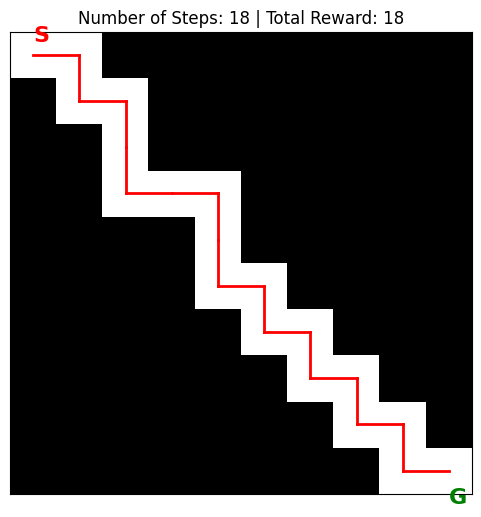

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

size = 10
maze = np.ones((size, size))

path = [(0, 0), (0, 1), (1, 1), (1, 2), (2, 2), (3, 2), (3, 3), (3, 4),
        (4, 4), (5, 4), (5, 5), (6, 5), (6, 6), (7, 6), (7, 7), (8, 7),
        (8, 8), (9, 8), (9, 9)]

for x, y in path:
    maze[x, y] = 0

plt.figure(figsize=(6, 6))
plt.imshow(maze, cmap="gray_r")

plt.text(0, -0.3, "S", color="red", fontsize=16, fontweight="bold")
plt.text(size - 1, size - 0.3, "G", color="green", fontsize=16, fontweight="bold")

for i in range(len(path) - 1):
    x1, y1 = path[i]
    x2, y2 = path[i + 1]
    plt.plot([y1, y2], [x1, x2], color="red", linewidth=2)

num_steps = len(path) - 1
total_reward = num_steps
plt.title(f"Number of Steps: {num_steps} | Total Reward: {total_reward}", fontsize=12)

plt.xticks([])
plt.yticks([])
plt.show()


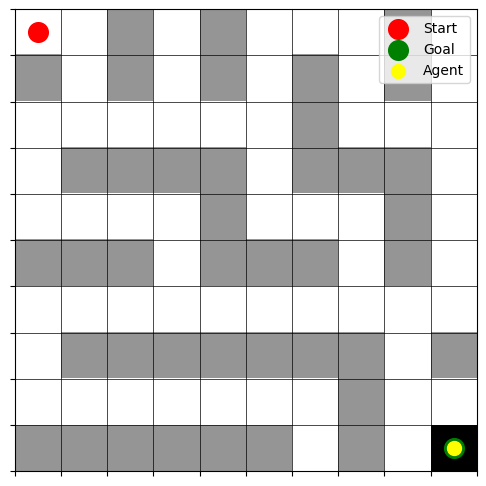

Steps: 24, Total Reward: 27
Final Steps: 24, Total Reward: 27


In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

# Labirint muhitini yaratamiz
class MazeGame:
    def __init__(self):
        # 10x10 murakkab labirint: 0 - bo'sh, 1 - devor
        self.maze = np.array([
            [0, 0, 1, 0, 1, 0, 0, 0, 1, 0],
            [1, 0, 1, 0, 1, 0, 1, 0, 1, 0],
            [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
            [0, 1, 1, 1, 1, 0, 1, 1, 1, 0],
            [0, 0, 0, 0, 1, 0, 0, 0, 1, 0],
            [1, 1, 1, 0, 1, 1, 1, 0, 1, 0],
            [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
            [0, 1, 1, 1, 1, 1, 1, 1, 0, 1],
            [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
            [1, 1, 1, 1, 1, 1, 0, 1, 0, 0]
        ])
        self.start = (0, 0)  # Qizil rangda boshlanadi
        self.goal = (9, 9)   # Yashil rangda maqsad
        self.reset()

    def reset(self):
        self.position = self.start
        self.done = False
        return self.position

    def step(self, action):
        x, y = self.position
        if action == 0:  # yuqoriga
            new_x, new_y = x - 1, y
        elif action == 1:  # o'ngga
            new_x, new_y = x, y + 1
        elif action == 2:  # pastga
            new_x, new_y = x + 1, y
        elif action == 3:  # chapga
            new_x, new_y = x, y - 1

        # Chegaralarni va devorlarni tekshirish
        if (0 <= new_x < 10 and 0 <= new_y < 10 and self.maze[new_x, new_y] != 1):
            self.position = (new_x, new_y)

        # Mukofot va o'yin tugashi
        if self.position == self.goal:
            self.done = True
            reward = 50  # Maqsadga yetganda katta mukofot
        elif self.maze[self.position[0], self.position[1]] == 1:
            reward = -10  # Devorga urilganda jarima
        else:
            reward = -1  # Har bir qadam uchun kichik jarima

        return self.position, reward, self.done

    def render(self):
        maze_copy = self.maze.copy()
        x, y = self.position
        maze_copy[x, y] = 2  # Agent pozitsiyasi (sariq rangda)

        # Matplotlib bilan vizualizatsiya
        plt.figure(figsize=(6, 6))
        plt.imshow(maze_copy, cmap='Greys', interpolation='none')  # 0 - oq, 1 - qora

        # Start (qizil) va Goal (yashil) ni qo'shamiz
        plt.scatter(self.start[1], self.start[0], c='red', s=200, label='Start')
        plt.scatter(self.goal[1], self.goal[0], c='green', s=200, label='Goal')
        plt.scatter(y, x, c='yellow', s=100, label='Agent')  # Agent sariq rangda

        plt.legend(loc='upper right')
        plt.grid(True, which='both', color='black', linestyle='-', linewidth=0.5)
        plt.xticks(np.arange(-0.5, 10, 1), [])
        plt.yticks(np.arange(-0.5, 10, 1), [])
        plt.show()

# Q-learning agenti
class QLearningAgent:
    def __init__(self, actions=4, learning_rate=0.1, discount_factor=0.9, epsilon=0.3):
        self.q_table = {}
        self.actions = actions
        self.lr = learning_rate
        self.gamma = discount_factor
        self.epsilon = epsilon  # 30% exploration, 70% exploitation

    def get_q_value(self, state, action):
        return self.q_table.get((state, action), 0.0)

    def choose_action(self, state):
        if random.random() < self.epsilon:  # Exploration
            return random.randint(0, self.actions - 1)
        else:  # Exploitation
            q_values = [self.get_q_value(state, a) for a in range(self.actions)]
            return np.argmax(q_values)

    def update_q_table(self, state, action, reward, next_state):
        old_q = self.get_q_value(state, action)
        next_max_q = max([self.get_q_value(next_state, a) for a in range(self.actions)])
        new_q = old_q + self.lr * (reward + self.gamma * next_max_q - old_q)
        self.q_table[(state, action)] = new_q

# O'qitish jarayoni
def train_agent(episodes=200):
    env = MazeGame()
    agent = QLearningAgent()

    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        steps = 0
        while not env.done:
            action = agent.choose_action(state)
            next_state, reward, done = env.step(action)
            agent.update_q_table(state, action, reward, next_state)
            state = next_state
            total_reward += reward
            steps += 1

        if episode % 20 == 0:
            print(f"Episode: {episode}, Steps: {steps}, Total Reward: {total_reward}")

    return agent

# Test qilish
def test_agent(agent, episodes=3):
    env = MazeGame()
    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        steps = 0
        print(f"\nTest Episode {episode + 1}:")
        while not env.done:
            action = agent.choose_action(state)
            state, reward, done = env.step(action)
            total_reward += reward
            steps += 1
            clear_output(wait=True)  # Oldingi ekranni tozalaydi
            env.render()
            print(f"Steps: {steps}, Total Reward: {total_reward}")
            time.sleep(0.5)  # Harakatni ko'rish uchun sekinlashtirish
        print(f"Final Steps: {steps}, Total Reward: {total_reward}")

# O'qitish va test qilish
agent = train_agent(episodes=200)  # 200 ta epizod bilan o'qitamiz
test_agent(agent, episodes=3)  # 3 ta test epizodi

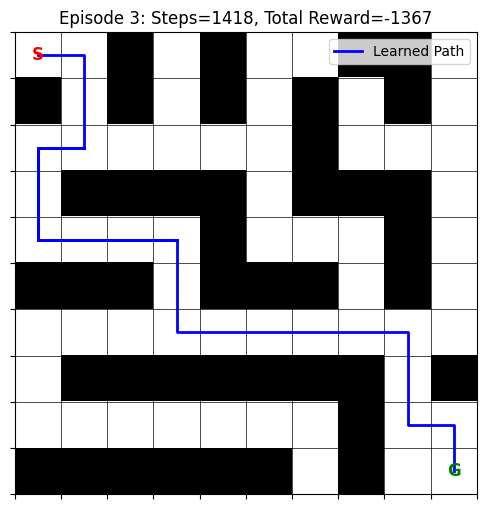


All Episode Results:
Episode 1: Steps=751447, Total Reward=-751396
Episode 2: Steps=114, Total Reward=-63
Episode 3: Steps=1418, Total Reward=-1367


In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

# Labirint muhitini yaratamiz
class MazeGame:
    def __init__(self):
        # 10x10 murakkab labirint: 0 - bo'sh, 1 - devor
        self.maze = np.array([
            [0, 0, 1, 0, 1, 0, 0, 1, 1, 0],
            [1, 0, 1, 0, 1, 0, 1, 0, 1, 0],
            [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
            [0, 1, 1, 1, 1, 0, 1, 1, 1, 0],
            [0, 0, 0, 0, 1, 0, 0, 0, 1, 0],
            [1, 1, 1, 0, 1, 1, 1, 0, 1, 0],
            [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
            [0, 1, 1, 1, 1, 1, 1, 1, 0, 1],
            [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
            [1, 1, 1, 1, 1, 1, 0, 1, 0, 0]
        ])
        self.start = (0, 0)  # Qizil rangda boshlanadi
        self.goal = (9, 9)   # Yashil rangda maqsad
        self.reset()

    def reset(self):
        self.position = self.start
        self.done = False
        self.path = [self.position]  # Agentning yo'lini saqlash uchun
        return self.position

    def step(self, action):
        x, y = self.position
        if action == 0:  # yuqoriga
            new_x, new_y = x - 1, y
        elif action == 1:  # o'ngga
            new_x, new_y = x, y + 1
        elif action == 2:  # pastga
            new_x, new_y = x + 1, y
        elif action == 3:  # chapga
            new_x, new_y = x, y - 1

        # Chegaralarni va devorlarni tekshirish
        if (0 <= new_x < 10 and 0 <= new_y < 10 and self.maze[new_x, new_y] != 1):
            self.position = (new_x, new_y)
            self.path.append(self.position)  # Yo'lga qo'shamiz

        # Mukofot va o'yin tugashi
        if self.position == self.goal:
            self.done = True
            reward = 50  # Maqsadga yetganda katta mukofot
        elif self.maze[self.position[0], self.position[1]] == 1:
            reward = -10  # Devorga urilganda jarima
        else:
            reward = -1  # Har bir qadam uchun kichik jarima

        return self.position, reward, self.done

    def render(self, episode=None, steps=None, total_reward=None):
        maze_copy = np.zeros((10, 10))
        for i in range(10):
            for j in range(10):
                if self.maze[i, j] == 1:
                    maze_copy[i, j] = 1  # Devorlar

        # Matplotlib bilan vizualizatsiya
        plt.figure(figsize=(6, 6))
        plt.imshow(maze_copy, cmap='binary', interpolation='none')  # 0 - oq, 1 - qora

        # Yo'lni chizish (ko'k rangda)
        if len(self.path) > 1:
            path_x, path_y = zip(*self.path)
            plt.plot(path_y, path_x, 'b-', linewidth=2, label='Learned Path')

        # Start (qizil) va Goal (yashil) ni qo'shamiz
        plt.text(self.start[1], self.start[0], 'S', color='red', fontsize=12, ha='center', va='center', weight='bold')
        plt.text(self.goal[1], self.goal[0], 'G', color='green', fontsize=12, ha='center', va='center', weight='bold')

        plt.grid(True, which='both', color='black', linestyle='-', linewidth=0.5)
        plt.xticks(np.arange(-0.5, 10, 1), [])
        plt.yticks(np.arange(-0.5, 10, 1), [])

        # Agar epizod ma'lumotlari bo'lsa, sarlavha sifatida ko'rsatamiz
        if episode is not None:
            plt.title(f"Episode {episode}: Steps={steps}, Total Reward={total_reward}")

        plt.legend(loc='upper right')
        plt.show()

# Q-learning agenti
class QLearningAgent:
    def __init__(self, actions=4, learning_rate=0.1, discount_factor=0.9, epsilon=0.3):
        self.q_table = {}
        self.actions = actions
        self.lr = learning_rate
        self.gamma = discount_factor
        self.epsilon = epsilon  # 30% exploration, 70% exploitation

    def get_q_value(self, state, action):
        return self.q_table.get((state, action), 0.0)

    def choose_action(self, state):
        if random.random() < self.epsilon:  # Exploration
            return random.randint(0, self.actions - 1)
        else:  # Exploitation
            q_values = [self.get_q_value(state, a) for a in range(self.actions)]
            return np.argmax(q_values)

    def update_q_table(self, state, action, reward, next_state):
        old_q = self.get_q_value(state, action)
        next_max_q = max([self.get_q_value(next_state, a) for a in range(self.actions)])
        new_q = old_q + self.lr * (reward + self.gamma * next_max_q - old_q)
        self.q_table[(state, action)] = new_q

# O'qitish jarayoni (grafiklar bilan)
def train_agent(episodes=40):
    env = MazeGame()
    agent = QLearningAgent()

    rewards = []  # Har bir epizod uchun mukofotlarni saqlash
    steps_list = []  # Har bir epizod uchun qadamlar sonini saqlash

    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        steps = 0
        while not env.done:
            action = agent.choose_action(state)
            next_state, reward, done = env.step(action)
            agent.update_q_table(state, action, reward, next_state)
            state = next_state
            total_reward += reward
            steps += 1

        rewards.append(total_reward)
        steps_list.append(steps)
        if episode % 10 == 0:
            print(f"Episode: {episode}, Steps: {steps}, Total Reward: {total_reward}")

    # Grafiklarni chizish
    plt.figure(figsize=(12, 5))

    # Reward per Episode
    plt.subplot(1, 2, 1)
    plt.plot(rewards, label='Cumulative Reward')
    plt.xlabel('Episode')
    plt.ylabel('Cumulative Reward')
    plt.title('Reward per Episode')
    plt.grid(True)

    # Steps per Episode
    plt.subplot(1, 2, 2)
    plt.plot(steps_list, label='Steps Taken')
    plt.xlabel('Episode')
    plt.ylabel('Steps Taken')
    plt.title('Steps per Episode')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # O'rtacha mukofot va qadamlar sonini chiqarish
    avg_reward = np.mean(rewards)
    avg_steps = np.mean(steps_list)
    print(f"The average reward is: {avg_reward}")
    print(f"The average steps is: {avg_steps}")

    return agent

# Test qilish
def test_agent(agent, episodes=3):
    env = MazeGame()
    episode_results = []  # Epizod natijalarini saqlash uchun

    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        steps = 0
        print(f"\nTest Episode {episode + 1}:")
        while not env.done:
            action = agent.choose_action(state)
            state, reward, done = env.step(action)
            total_reward += reward
            steps += 1

        # Har bir epizod uchun yo'lni ko'rsatish
        clear_output(wait=True)
        env.render(episode + 1, steps, total_reward)
        episode_results.append((episode + 1, steps, total_reward))

    # Barcha epizodlar natijasini pastda chiqarish
    print("\nAll Episode Results:")
    for ep, st, tr in episode_results:
        print(f"Episode {ep}: Steps={st}, Total Reward={tr}")

# O'qitish va test qilish
agent = train_agent(episodes=40)  # 40 ta epizod bilan o'qitamiz
test_agent(agent, episodes=3)  # 3 ta test epizodi